In [1]:
import matplotlib.pyplot as plt
from z3 import *
from string import ascii_uppercase
import time
import requests
from bs4 import BeautifulSoup
from IPython.display import Markdown, display,Image,HTML
from ortools.sat.python import cp_model

In [2]:
url='https://www.janestreet.com/puzzles/some-ones-somewhere-index/'
res = requests.get(url)
soup = BeautifulSoup(res.content, 'html.parser')
x =[text for text in soup.body.stripped_strings]
#display([(i,j) for i,j in enumerate(x)])
display(Markdown(" ".join(x[15:18])))

(The answer to this month’s puzzle – which can be seen here – is a sentence.)

In [3]:
def solve_board(pre_filled_blocks):
    
    BOARD_SIZE = 45
    
    # Pre-filled square blocks: (x, y, size)       
    filled_counts = {x:Sum([i[2]==x for i in pre_filled_blocks ]) for x in range(1,10)}
    
    # Tiles to place: n of size n×n
    tiles = []
    for size in range(1, 10):  # sizes 1 to 9
        for count in range(size-filled_counts[size]):  # count = size
            tiles.append((size, "{}_{}".format(size,count)))
    
    solver = Tactic('smt').solver()
    
    positions = {}
    for size, name in tiles:
        x = Int("x_{}".format(name))
        y = Int("y_{}".format(name))
        positions[name] = (x, y)
    
        solver.add(x >= 0, y >= 0)
        solver.add(x + size <= BOARD_SIZE)
        solver.add(y + size <= BOARD_SIZE)
    
    # No overlap between tiles
    def no_overlap(tile1, tile2):
        size1, (x1, y1) = tile1
        size2, (x2, y2) = tile2
        return Or(
            x1 + size1 <= x2,
            x2 + size2 <= x1,
            y1 + size1 <= y2,
            y2 + size2 <= y1
        )
    
    tile_vars = [(size, positions[name]) for size, name in tiles]
    for i in range(len(tile_vars)):
        for j in range(i + 1, len(tile_vars)):
            solver.add(no_overlap(tile_vars[i], tile_vars[j]))
    
    # Prevent tiles from overlapping any blocked regions
    for size, name in tiles:
        x, y = positions[name]
        for (bx, by, bsize) in pre_filled_blocks:
            solver.add(Or(
                x + size <= bx,         # tile is left of block
                x >= bx + bsize,        # tile is right of block
                y + size <= by,         # tile is above block
                y >= by + bsize         # tile is below block
            ))
    
    # Solve
    if solver.check() == sat:
        model = solver.model()
        solution = [(size, model[positions[name][0]].as_long(), model[positions[name][1]].as_long()) for size, name in tiles]
    
        # Plot
        fig, ax = plt.subplots(figsize=(4, 4))
        ax.set_xlim(0, BOARD_SIZE)
        ax.set_ylim(0, BOARD_SIZE)
        ax.set_aspect('equal')
        ax.invert_yaxis()
    
        for size, x, y in solution:
            rect = plt.Rectangle((x, y), size, size, fill=True, edgecolor='black', linewidth=1)
            ax.add_patch(rect)
            ax.text(x + size / 2, y + size / 2, "{}".format(size), ha='center', va='center', fontsize=8, color='white')
    
        # Plot blocked regions
        for bx, by, bsize in pre_filled_blocks:
            blocked = plt.Rectangle((bx, by), bsize, bsize, color='red', alpha=0.6)
            ax.add_patch(blocked)
    
        plt.grid(True, which='both', color='gray', linewidth=0.5, linestyle='--')
    else:
        print("No solution found.")

    return solution

In [4]:
# def solve_board(pre_filled_blocks):
    
#     BOARD_SIZE = 45
    
#     # Pre-filled square blocks: (x, y, size)       
#     filled_counts = {x:Sum([i[2]==x for i in pre_filled_blocks ]) for x in range(1,10)}
    
    
#     model = cp_model.CpModel()
    
    
#     # Tiles: n tiles of size n x n
#     tiles = []
#     for size in range(1, 10):
#         for i in range(size-filled_counts[size]):
#             tiles.append((size, f"{size}_{i}"))
    
#      # Create variables and intervals for real tiles
#     tile_vars = {}
#     x_intervals = []
#     y_intervals = []
    
#     for size, name in tiles:
#         x = model.NewIntVar(0, BOARD_SIZE - size, f"x_{name}")
#         y = model.NewIntVar(0, BOARD_SIZE - size, f"y_{name}")
#         x_size = model.NewConstant(size)
#         y_size = model.NewConstant(size)
    
#         x_interval = model.NewIntervalVar(x, x_size, x + size, f"x_int_{name}")
#         y_interval = model.NewIntervalVar(y, y_size, y + size, f"y_int_{name}")
    
#         tile_vars[name] = (size, x, y)
#         x_intervals.append(x_interval)
#         y_intervals.append(y_interval)
    
#     # Create constant intervals for blocked regions
#     for i, (bx, by, bsize) in enumerate(pre_filled_blocks):
#         x = model.NewConstant(bx)
#         y = model.NewConstant(by)
#         size_const = model.NewConstant(bsize)
    
#         x_int = model.NewIntervalVar(x, size_const, bx + bsize, f"block_x_{i}")
#         y_int = model.NewIntervalVar(y, size_const, by + bsize, f"block_y_{i}")
    
#         x_intervals.append(x_int)
#         y_intervals.append(y_int)
    
#     # Enforce non-overlap for all tiles including blocked areas
#     model.AddNoOverlap2D(x_intervals, y_intervals)
    
#     # Optional: decision strategy
#     # all_vars = [tile_vars[name][1] for _, name in tiles] + [tile_vars[name][2] for _, name in tiles]
#     # model.AddDecisionStrategy(
#     #     all_vars,
#     #     cp_model.CHOOSE_LOWEST_MIN,
#     #     cp_model.SELECT_MIN_VALUE
#     # )
    
#     # Solve
#     solver = cp_model.CpSolver()
#     # solver.parameters.max_time_in_seconds = 60
#     # solver.parameters.num_search_workers = 4
    
#     status = solver.Solve(model)
    
#     if status in [cp_model.FEASIBLE, cp_model.OPTIMAL]:
#         print("Solution found.")
#         solution = [(size, solver.Value(x), solver.Value(y)) for size, x, y in [(
#             size, tile_vars[name][1], tile_vars[name][2]) for size, name in tiles]]
    
#         # Plotting
#         fig, ax = plt.subplots(figsize=(10, 10))
#         ax.set_xlim(0, BOARD_SIZE)
#         ax.set_ylim(0, BOARD_SIZE)
#         ax.set_aspect('equal')
#         ax.invert_yaxis()
#         ax.set_title("Partridge Tiling with Blocked Areas (NoOverlap2D)")
    
#         for size, x, y in solution:
#             rect = plt.Rectangle((x, y), size, size, edgecolor='black', facecolor='skyblue')
#             ax.add_patch(rect)
#             ax.text(x + size / 2, y + size / 2, str(size), ha='center', va='center', color='white', fontsize=8)
    
#         for bx, by, bsize in pre_filled_blocks:
#             brect = plt.Rectangle((bx, by), bsize, bsize, color='red', alpha=0.6)
#             ax.add_patch(brect)
    
#         plt.grid(True, linestyle='--', linewidth=0.5)
#         plt.show()
    
#     else:
#         print("No solution found.")
    
# #     return solution

Puzzle Answer is : SUMOFCUBESISSQUARE
Took 85.42 seconds


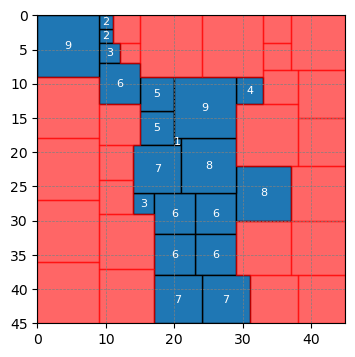

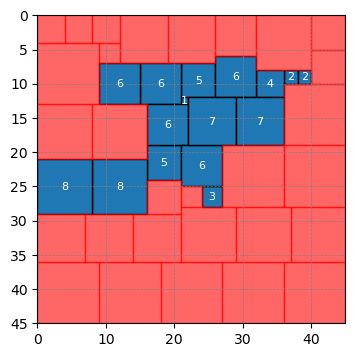

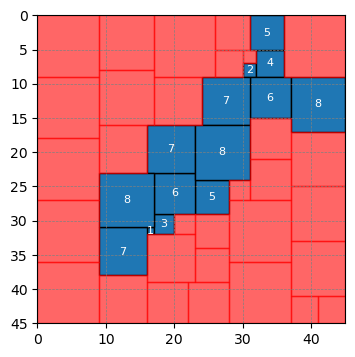

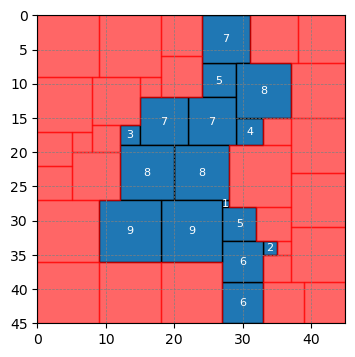

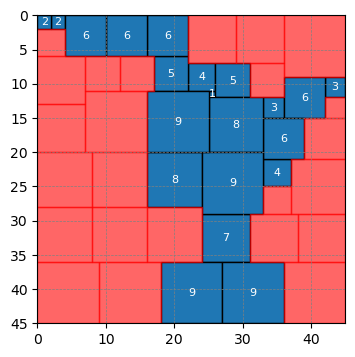

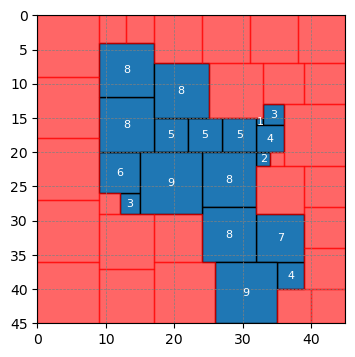

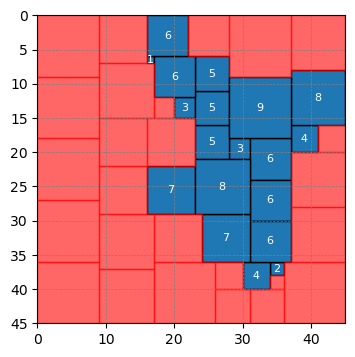

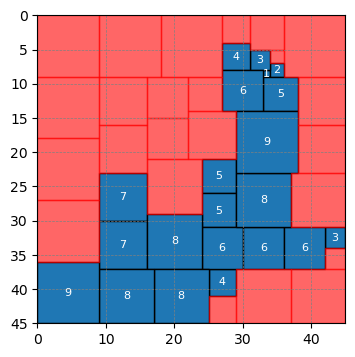

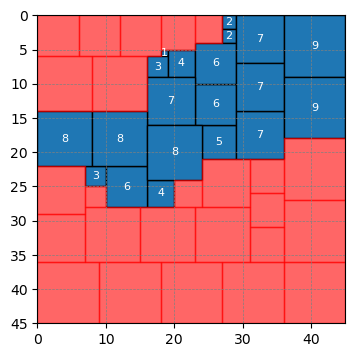

In [12]:
start = time.time()
boards =  [[(0, 36, 9), (0, 27, 9), (0, 18, 9), (0, 9, 9), (29, 13, 9), (15, 0, 9), (24, 0, 9), (37, 0, 8), (37, 22, 8), (29, 30, 8), (37, 30, 8), (9, 37, 8),
            (9, 29, 8), (38, 38, 7), (31, 38, 7), (38, 15, 7), (38, 8, 7), (9, 13, 6), (9, 24, 5), (9, 19, 5), (33, 8, 5), (33, 4, 4), (33, 0, 4), (12, 4, 3), (11, 0, 4)],
           
          [(0, 36, 9), (9, 36, 9), (0, 13, 8), (37, 28, 8), (29, 28, 8), (18, 36, 9), (27, 36, 9), (36, 36, 9), (21, 28, 8), (0, 29, 7), (7, 29, 7), (14, 29, 7), (8, 13, 8), (32, 0, 8), (40, 5, 5), (40, 0, 5), (36, 19, 9), (27, 19, 9), (36, 10, 9),
           (16, 24, 5), (21, 25, 3), (0, 0, 4), (4, 0, 4), (8, 0, 4), (0, 4, 9), (9, 4, 3), (12, 0, 7), (19, 0, 7), (26, 0, 6)],
           
           [(0, 18, 9), (0, 27, 9), (0, 36, 9), (0, 9, 9), (0, 0, 9), (9, 0, 8), (9, 8, 8), (9, 16, 7), (9, 38, 7), (16, 39, 6), (22, 39, 6), (16, 32, 7), (20, 29, 3), (23, 34, 5), (23, 29, 5), (28, 36, 9), (28, 27, 9), (37, 41, 4), (41, 41, 4),
            (37, 33, 8), (37, 25, 8), (37, 17, 8), (31, 21, 6), (31, 15, 6), (36, 0, 9), (17, 0, 9), (17, 9, 7), (26, 0, 5), (26, 5, 4), (30, 5, 2), (28, 24, 3)],

           [(0, 36, 9), (0, 27, 9), (9, 36, 9), (18, 36, 9), (0, 22, 5), (0, 17, 5), (5, 17, 3), (8, 16, 4), (5, 20, 7), (8, 9, 7), (0, 9, 8), (0, 0, 9), (9, 0, 9), (15, 9, 3), (18, 6, 6), (18, 0, 6), 
            (38, 0, 7), (31, 0, 7), (37, 23, 8), (37, 15, 8), (37, 7, 8), (37, 31, 8), (39, 39, 6), (33, 39, 6), (33, 35, 4), (35, 33, 2), (32, 28, 5), (28, 19, 9), (33, 15, 4)],
           
          [(0, 36, 9), (9, 36, 9), (0, 28, 8), (8, 28, 8), (16, 28, 8), (0, 20, 8), (8, 20, 8), (0, 13, 7), (0, 6, 7), (7, 11, 9), (7, 6, 5), (12, 6, 5), (0, 2, 4), (36, 0, 9), (29, 0, 7),
           (22, 0, 7), (31, 7, 5), (36, 36, 9), (31, 29, 7), (38, 29, 7), (33, 25, 4), (37, 21, 8), (39, 15, 6), (42, 12, 3)],

           [(0, 27, 9), (0, 36, 9), (0, 18, 9), (0, 9, 9), (0, 0, 9), (9, 37, 8), (9, 29, 8), (9, 26, 3), (13, 0, 4), (9, 0, 4), (17, 0, 7), (31, 0, 7), (24, 0, 7), (38, 0, 7), (39, 28, 6), (39, 34, 6),
            (39, 22, 6), (35, 40, 5), (40, 40, 5), (17, 36, 9), (17, 29, 7), (36, 13, 9), (33, 7, 6), (39, 7, 6), (25, 7, 8), (32, 22, 7), (34, 20, 2)],

           [(0, 18, 9), (0, 0, 9), (0, 9, 9), (0, 27, 9), (17, 36, 9), (36, 36, 9), (0, 36, 9), (28, 0, 9), (37, 0, 8), (37, 20, 8), (37, 28, 8), (9, 37, 8), (9, 29, 8), (9, 7, 8), (9, 22, 7), (9, 15, 7), (9, 0, 7),
            (17, 12, 3), (16, 15, 7), (26, 40, 5), (31, 40, 5), (34, 38, 2), (26, 36, 4), (41, 16, 4), (22, 0, 6), (17, 29, 7)],
           
           [(0, 0, 9), (0, 9, 9), (0, 18, 9), (0, 27, 9), (18, 0, 9), (9, 0, 9), (9, 9, 7), (9, 16, 7), (16, 9, 6), (16, 15, 6), (22, 14, 7), (22, 9, 5), (16, 21, 8), (36, 0, 9), (31, 0, 5), (34, 5, 2), (27, 0, 4),
            (38, 9, 7), (38, 16, 7), (37, 23, 8), (37, 37, 8), (29, 37, 8), (25, 41, 4), (42, 34, 3)],
           
           [(36, 36, 9), (18, 36, 9), (9, 36, 9), (0, 36, 9), (27, 36, 9), (36, 27, 9), (36, 18, 9), (31, 31, 5), (31, 26, 5), (31, 21, 5), (23, 28, 8), (15, 28, 8), (7, 28, 8), (0, 29, 7), (0, 22, 7), (24, 21, 7),
            (20, 24, 4), (7, 25, 3), (6, 0, 6), (12, 0, 6), (0, 0, 6), (18, 0, 5), (23, 0, 4), (0, 6, 8), (8, 6, 8)]

          ]

solution = []
row = 0
col = 0

for board in boards[:]:
    output = solve_board(board)
    #print(output)
    solution += [y+col for e,x,y in output if e==1]
    solution += [x+row for e,x,y in output if e==1]   
    row += 45
    if row == 45*3:
        row = 0
        col +=45
    
print("Puzzle Answer is :","".join([ascii_uppercase[i%26] for i in solution]))
print("Took {:.2f} seconds".format(time.time()-start))